# Connectivity

Compare three meanings of “connect these nodes” on one graph, then require paths to follow directed arcs.

Download {download}`this notebook <connectivity.ipynb>` to run it locally.
Install the example dependencies with `pip install steinerpy matplotlib ipykernel`.
All solves below use the default HiGHS backend.

In [1]:
import logging
import matplotlib.pyplot as plt
import networkx as nx
from steinerpy import Problem

# Keep the example output focused on results; solver errors still propagate.
logging.getLogger().setLevel(logging.WARNING)
logging.getLogger("steinerpy").setLevel(logging.WARNING)
plt.rcParams.update({"figure.dpi": 140, "font.size": 11, "figure.facecolor": "white"})

## One graph, three requirements

The two pairs A–B and C–D have inexpensive local edges. Joining the pairs
requires the more expensive B–C edge. Each solve uses the same graph.

In [2]:
graph = nx.Graph()
graph.add_weighted_edges_from([("A", "B", 1), ("B", "C", 4), ("C", "D", 2)])
positions = {"A": (0, 1), "B": (1, 0), "C": (2, 0), "D": (3, 1)}
tree = Problem(graph, terminals=["A", "B", "C", "D"]).get_solution(time_limit=30)
forest = Problem(graph, terminals=[["A", "B"], ["C", "D"]]).get_solution(time_limit=30)
groups = [["A", "B"], ["C", "D"]]
choice = Problem(graph, groups=groups).get_solution(time_limit=30)
for (name, solution, cost) in [('Tree', tree, 7), ('Forest', forest, 3), ('Groups', choice, 4)]:
    print(f'{name}: cost {solution.objective:g}')

Tree: cost 7
Forest: cost 3
Groups: cost 4


In [3]:
for name, solution, cost in [("Tree", tree, 7), ("Forest", forest, 3), ("Groups", choice, 4)]:
    assert solution.objective == cost and solution.gap == 0
    assert sum(graph[u][v]["weight"] for u, v in solution.edges) == cost
tree_graph = graph.edge_subgraph(tree.edges)
assert nx.is_connected(tree_graph) and set(tree_graph) == set(graph)
forest_graph = graph.edge_subgraph(forest.edges)
assert nx.has_path(forest_graph, "A", "B") and nx.has_path(forest_graph, "C", "D")
assert nx.number_connected_components(forest_graph) == 2
choice_graph = graph.edge_subgraph(choice.edges)
assert nx.is_connected(choice_graph)
assert all(set(group) & set(choice_graph) for group in groups)

The tree requires every listed node. The forest requires each pair to
connect internally; connecting the pairs is unnecessary here. Forest paths
may still share edges when that reduces cost.

Groups are alternatives: one connected component must contain at least one
member of each group. Here the cheapest choices are B and C.

In [4]:
def draw(graph, positions, ax, title, solution=None, terminals=(), groups=(), root=None):
    """Plot original edges and highlight a returned selection at fixed positions."""
    ax.set_facecolor("white")
    arrow_options = {"arrowsize": 18} if graph.is_directed() else {}
    nx.draw_networkx_edges(graph, positions, ax=ax, edge_color="#b8bec5",
                           style="dashed", width=1.3, node_size=620, **arrow_options)
    if solution is not None:
        nx.draw_networkx_edges(graph, positions, ax=ax, edgelist=solution.edges,
                               edge_color="#007a78", width=3, node_size=620,
                               **arrow_options)
    marked = set(terminals) | {node for group in groups for node in group}
    if root is not None:
        marked.add(root)
    ordinary = [node for node in graph if node not in marked]
    nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=ordinary,
                           node_color="#f5f7fa", edgecolors="#374151", node_size=620)
    if terminals:
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=list(terminals),
                               node_shape="s", node_color="#ffdc8b",
                               edgecolors="#374151", node_size=620)
    for idx, group in enumerate(groups):
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=group,
                               node_shape=["s", "^"][idx % 2],
                               node_color=["#c2e4f5", "#ffd3a8"][idx % 2],
                               edgecolors="#374151", node_size=620)
    if root is not None:
        nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=[root],
                               node_shape="D", node_color="#dbcdf3",
                               edgecolors="#374151", node_size=620)
    nx.draw_networkx_labels(graph, positions, ax=ax, font_size=11,
                            font_color="#17212b")
    nx.draw_networkx_edge_labels(graph, positions, ax=ax,
                                 edge_labels=nx.get_edge_attributes(graph, "weight"),
                                 font_size=10, rotate=False)
    ax.set_title(title, color="#17212b", pad=12)
    ax.margins(0.25)
    ax.set_axis_off()

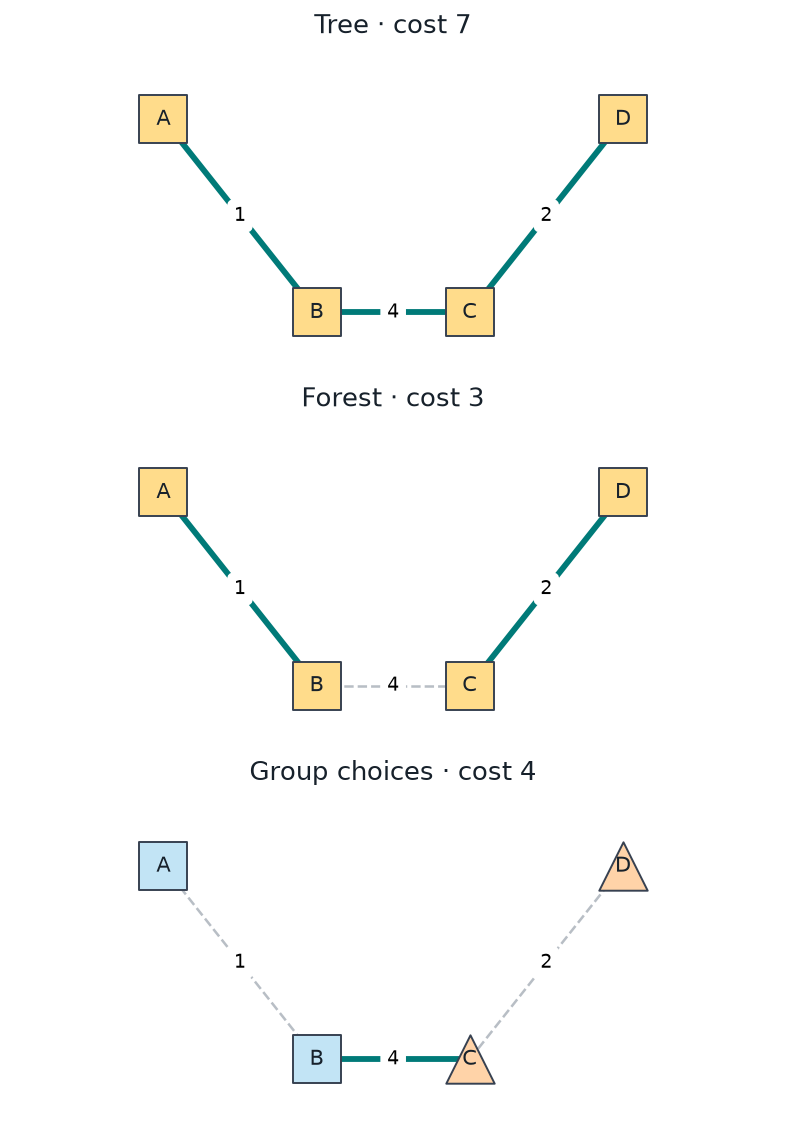

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(5.5, 8), layout="constrained")
draw(graph, positions, axes[0], "Tree · cost 7", tree, terminals=list(graph))
draw(graph, positions, axes[1], "Forest · cost 3", forest, terminals=list(graph))
draw(graph, positions, axes[2], "Group choices · cost 4", choice, groups=groups)
plt.show()

## Directed paths

With a `DiGraph`, the root must reach each terminal following the arrows.
The inexpensive D→R arc cannot be traversed from R to D.

In [6]:
directed = nx.DiGraph()
directed.add_weighted_edges_from([("R", "B", 1), ("B", "D", 2), ("D", "R", 1)])
directed_positions = {"R": (0, 0), "B": (1, 1), "D": (2, 0)}
rooted = Problem(directed, root="R", terminals=["D"]).get_solution(time_limit=30)
print(f"Directed cost: {rooted.objective:g}")

Directed cost: 3


In [7]:
assert rooted.objective == 3 and rooted.gap == 0
assert nx.has_path(directed.edge_subgraph(rooted.edges), "R", "D")
assert set(rooted.edges) == {("R", "B"), ("B", "D")}

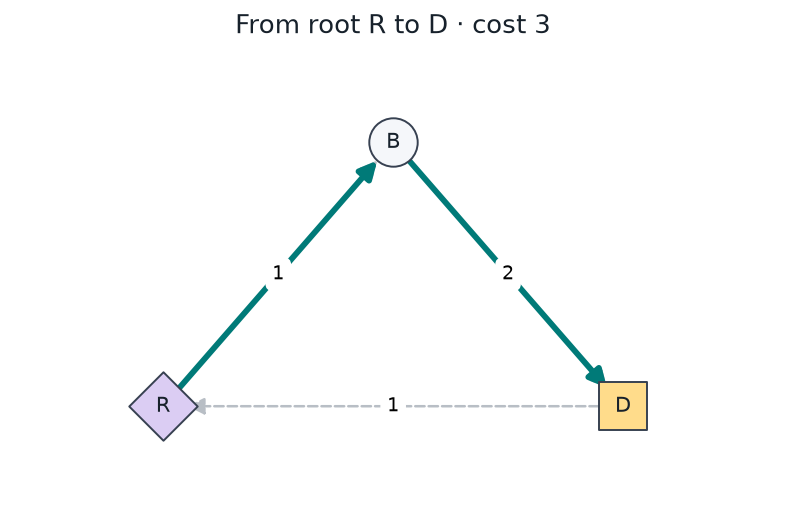

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 3.5), layout="constrained")
draw(directed, directed_positions, ax, "From root R to D · cost 3", rooted,
     terminals=["D"], root="R")
plt.show()

You can also combine `root` with groups on a directed graph. See the
[modelling guide](../guide/variants.md) for the inputs and the
[compatibility reference](../reference/compatibility.md) for combinations.
Next, add [costs and budgets](costs_and_budgets.ipynb).